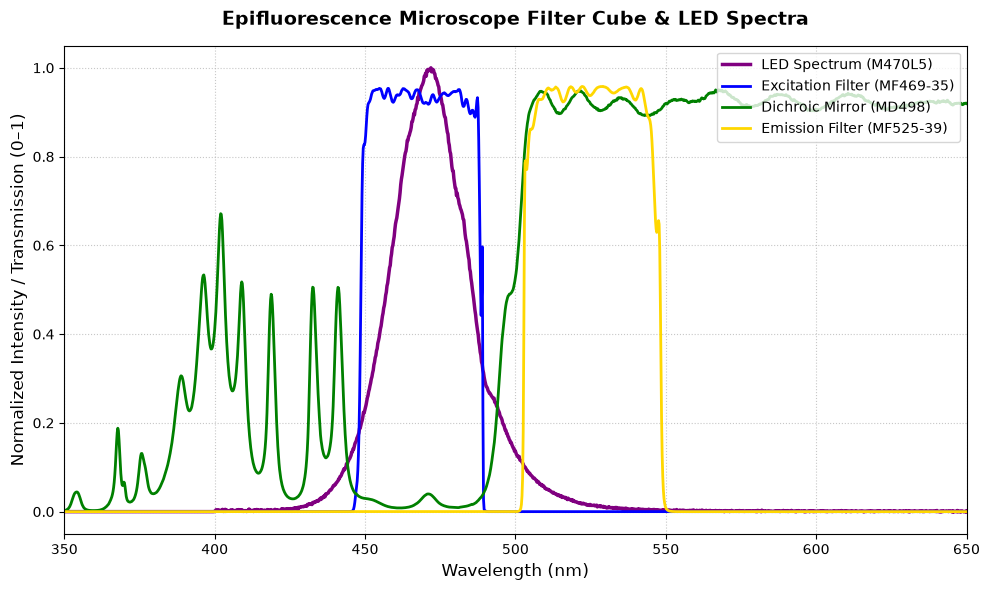

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load Thorlabs LED Spectrum (m470l5_data.xlsx)
# Note: The LED data file stores header labels in row 0, columns 2 and 3.
df_led = pd.read_excel('m470l5_data.xlsx', header=None)
led_wavelength = pd.to_numeric(df_led.iloc[1:, 2], errors='coerce')
led_intensity = pd.to_numeric(df_led.iloc[1:, 3], errors='coerce')

# 2. Load Filter Files (mf469-35.xlsx, md498.xlsx, mf525-39.xlsx)
def load_filter_data(filepath):
    df = pd.read_excel(filepath)
    return df['Wavelength (nm)'], df['% Transmission'] / 100.0  # Convert % to fraction (0 to 1)

ex_wl, ex_trans = load_filter_data('mf469-35.xlsx')       # Excitation filter
dich_wl, dich_trans = load_filter_data('md498.xlsx')       # Dichroic mirror
em_wl, em_trans = load_filter_data('mf525-39.xlsx')       # Emission filter

# 3. Create the Epifluorescence Spectra Plot
plt.figure(figsize=(10, 6))

# Plot Thorlabs LED in Purple
plt.plot(led_wavelength, led_intensity, color='purple', label='LED Spectrum (M470L5)', linewidth=2.5)

# Plot Excitation Filter Bandpass in Blue
plt.plot(ex_wl, ex_trans, color='blue', label='Excitation Filter (MF469-35)', linewidth=2, linestyle='-')

# Plot Dichroic Mirror in Green
plt.plot(dich_wl, dich_trans, color='green', label='Dichroic Mirror (MD498)', linewidth=2, linestyle='-')

# Plot Emission Bandpass Filter in Yellow (using 'gold' for high contrast on white background)
plt.plot(em_wl, em_trans, color='gold', label='Emission Filter (MF525-39)', linewidth=2, linestyle='-')

# 4. Formatting and Labels
plt.title('Epifluorescence Microscope Filter Cube & LED Spectra', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Wavelength (nm)', fontsize=12)
plt.ylabel('Normalized Intensity / Transmission (0–1)', fontsize=12)

# Focus view on the relevant optical window (350 nm to 650 nm)
plt.xlim(350, 650)
plt.ylim(-0.05, 1.05)

plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()

# Save and Display
plt.savefig('epifluorescence_system_spectra.png', dpi=300)
plt.savefig('epifluorescence_system_spectra.svg')
plt.show()

In [9]:
# 1. Load Thorlabs LED Spectrum (m470l5_data.xlsx)
df_led = pd.read_excel('m470l5_data.xlsx', header=None)
led_wavelength = pd.to_numeric(df_led.iloc[2:, 2], errors='coerce').values
led_intensity = pd.to_numeric(df_led.iloc[2:, 3], errors='coerce').values

# 2. Load Excitation Filter Data (mf469-35.xlsx)
df_ex = pd.read_excel('mf469-35.xlsx')
ex_wavelength = df_ex['Wavelength (nm)'].values
ex_transmission_pct = df_ex['% Transmission'].values
ex_transmission = ex_transmission_pct / 100.0  # Convert percentage (0-100) to fraction (0-1)

interp_transmission = np.interp(led_wavelength, ex_wavelength, ex_transmission, left=0.0, right=0.0)

total_led_emission = np.trapezoid(led_intensity, led_wavelength)
transmitted_led_emission = np.trapezoid(led_intensity * interp_transmission, led_wavelength)
percentage_transmitted = (transmitted_led_emission / total_led_emission) * 100.0

print(f"Estimated LED light transmitted through excitation filter: {percentage_transmitted:.2f}%")

Estimated LED light transmitted through excitation filter: 77.15%
